## H2 - Age and Attempts to Success

Younger clients require fewer attempts to successfully
complete the process than older clients.

### Methodology

We consider a process successful when:

- The session starts at the 'start' step.
- The session ends at the 'confirm' step.
- The session takes 360 seconds or less.

Each session (visit_id) is considered one attempt.

We organize the sessions by date and time for each client
to find how many attempts they needed to succeed for
the first time in our dataset.

We do not count any attempts after the first successful
session.

### 1. Data Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

sessions_master = pd.read_csv('../data/clean/sessions_data_master.csv')
clients_data = pd.read_csv('../data/raw/cleaned_client_data.csv')
web_data = pd.read_csv("../data/raw/cleaned_web_data.csv")

clients_data = clients_data.drop(columns=["Unnamed: 0"])
web_data = web_data.drop(columns=["Unnamed: 0"])

### 2. Defining a Successful Process

In [2]:
# Identifying sessions that meet our success criteria

sessions_master["successful_process"] = (
    (sessions_master["starts_at_start"] == True) &
    (sessions_master["last_step"] == "confirm") &
    (sessions_master["total_time_seconds"] <= 360)
)

display("Completed sessions:", sessions_master["completed"].value_counts())
print("\n")
display("Successful sessions:", sessions_master["successful_process"].value_counts())

'Completed sessions:'

completed
True     37879
False    31568
Name: count, dtype: int64

'Successful sessions:'

successful_process
False    48407
True     21040
Name: count, dtype: int64

In [3]:
# Investigating these records

completed_sessions = sessions_master[sessions_master["completed"] == True]

print("Didn't start at 'start':", (completed_sessions["starts_at_start"] == False).sum())
print("Didn't end at 'confirm':", (completed_sessions["last_step"] != "confirm").sum())
print("Lasted longer than 360 seconds:", (completed_sessions["total_time_seconds"] > 360).sum())

Didn't start at 'start': 5074
Didn't end at 'confirm': 952
Lasted longer than 360 seconds: 11817


Of the 37,879 completed sessions, 21,040 meet our
definition of a successful process.

The remaining 16,839 sessions do not meet at least one
of our three success conditions.

Some sessions may not meet more than one condition.


In [4]:
# Comparing successful sessions by variation

display(sessions_master["variation"].value_counts(dropna=False))

# Comparing session performance by variation

success_by_variation = sessions_master.pivot_table(
    columns="variation",
    values=["completed", "successful_process", "visit_id"],
    aggfunc={
        "completed": "mean",
        "successful_process": "mean",
        "visit_id": "count"
    }
)

display(success_by_variation.round(4))

variation
Test       37204
Control    32243
Name: count, dtype: int64

variation,Control,Test
completed,0.4990,0.5857
successful_process,0.2872,0.3167
visit_id,32243.0000,37204.0000


In [5]:
# Calculating the difference between Test and Control

success_by_variation["Difference (Test - Control)"] = (
    success_by_variation["Test"] - success_by_variation["Control"])

display(success_by_variation.round(4))

# Calculating the differences in percentage points

completion_difference = (success_by_variation.loc["completed", "Difference (Test - Control)"] * 100)

success_difference = (success_by_variation.loc["successful_process", "Difference (Test - Control)"] * 100)

print(f"Difference in completion rates: {completion_difference:.2f} percentage points")
print(f"Difference in success rates: {success_difference:.2f} percentage points")

variation,Control,Test,Difference (Test - Control)
completed,0.4990,0.5857,0.0868
successful_process,0.2872,0.3167,0.0295
visit_id,32243.0000,37204.0000,4961.0000


Difference in completion rates: 8.68 percentage points
Difference in success rates: 2.95 percentage points


In [6]:
# Calculating the success rate among completed sessions

completed_sessions.groupby("variation")["successful_process"].mean().mul(100).round(2)

variation
Control    57.55
Test       54.06
Name: successful_process, dtype: float64

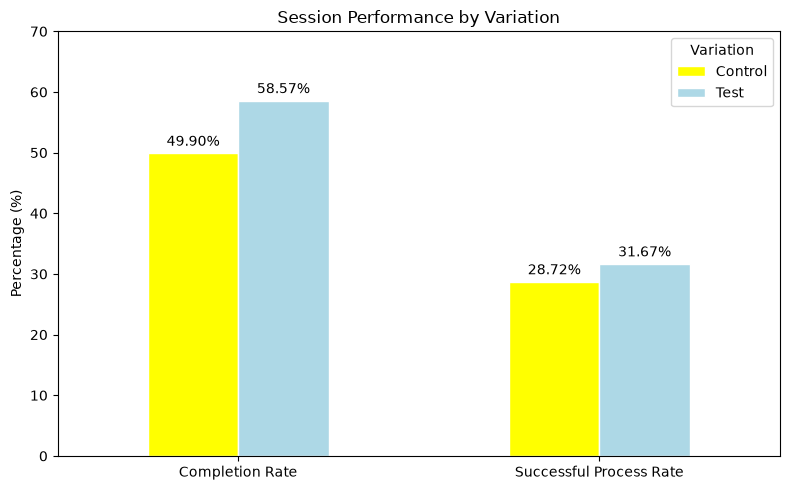

In [7]:
# Visualising completion and success rates by variation

success_by_variation.loc[
    ["completed", "successful_process"],
    ["Control", "Test"]
].mul(100).plot(
    kind="bar",
    color=["yellow", "lightblue"],
    figsize=(8, 5),
    edgecolor="white"
)

plt.title("Session Performance by Variation")
plt.ylabel("Percentage (%)")
plt.xlabel("")
plt.xticks(
    [0, 1],
    ["Completion Rate", "Successful Process Rate"],
    rotation=0
)
plt.ylim(0, 70)
plt.legend(title="Variation")
plt.tight_layout()
for container in plt.gca().containers:
    plt.bar_label(container, fmt="%.2f%%", padding=3)
plt.savefig("../figures/session_by_var.png", dpi=300, bbox_inches="tight")
plt.show()


#### Findings

The Test group has a higher completion rate (58.57%)
than the Control group (49.90%), with a difference
of 8.68 percentage points.

The Test group also has a higher successful process
rate (31.67% compared to 28.72%), but the difference
is smaller, at 2.95 percentage points.

However, when looking only at completed sessions,
57.55% meet our success conditions in the Control
group, compared to 54.06% in the Test group.

This shows that although more sessions are completed
with the new interface, a smaller percentage of
completed sessions meet all three success conditions.

Later in our analysis, we will check if the new
interface improves the success rate and number
of attempts for different age groups.

### 3. Calculating Attempts to Success

In [8]:
# Need to add timestamps of the sessions to understand when they happened in chronological order
web_data.head()

,client_id,visitor_id,visit_id,process_step,date_time,variation
0,555,402506806_56087378777,637149525_38041617439_716659,confirm,2017-04-15 13:00:34,Test
1,555,402506806_56087378777,637149525_38041617439_716659,step_3,2017-04-15 13:00:14,Test
2,555,402506806_56087378777,637149525_38041617439_716659,step_2,2017-04-15 12:58:35,Test
3,555,402506806_56087378777,637149525_38041617439_716659,step_1,2017-04-15 12:58:03,Test
4,555,402506806_56087378777,637149525_38041617439_716659,start,2017-04-15 12:57:56,Test


In [9]:
# adjusting data type

web_data["date_time"] = pd.to_datetime(web_data["date_time"])

# find the first recorded timestamp of each session

session_start = (
    web_data.groupby(["client_id", "visit_id"])["date_time"]
    .min()
    .reset_index()
)

session_start = session_start.rename(columns={"date_time": "session_start_time"})

session_start.head()

,client_id,visit_id,session_start_time
0,555,637149525_38041617439_716659,2017-04-15 12:57:56
1,647,40369564_40101682850_311847,2017-04-12 15:41:28
2,934,7076463_57954418406_971348,2017-04-18 02:36:30
3,1028,557292053_87239438319_391157,2017-04-08 18:51:28
4,1104,543158812_46395476577_767725,2017-06-12 07:49:18


In [10]:
# Merge session start time column to our master table

sessions_master = sessions_master.merge(session_start, on=["client_id", "visit_id"], how="left")

sessions_master.head()

,client_id,visit_id,step_count,last_step,variation,completed,journey_status,out_of_order_count,step_backs_count,repeats_count,skips_count,starts_at_start,follows_right_order,total_time_seconds,starts_count,multiple_starts,confirms_count,multiple_confirms,successful_process,session_start_time
0,555,637149525_38041617439_716659,5,confirm,Test,True,Completed,1,0,0,0,True,False,158.0,1,False,1,False,True,2017-04-15 12:57:56
1,647,40369564_40101682850_311847,5,confirm,Test,True,Completed,1,0,0,0,True,False,377.0,1,False,1,False,False,2017-04-12 15:41:28
2,934,7076463_57954418406_971348,4,start,Test,False,Incomplete,3,0,3,0,True,False,142.0,4,True,0,False,False,2017-04-18 02:36:30
3,1028,557292053_87239438319_391157,9,step_1,Control,False,Incomplete,1,0,0,0,True,False,538.0,1,False,0,False,False,2017-04-08 18:51:28
4,1104,543158812_46395476577_767725,1,start,Control,False,Incomplete,0,0,0,0,True,True,0.0,1,False,0,False,False,2017-06-12 07:49:18


In [11]:
# organizing the sessions chronologically

sessions_master = sessions_master.sort_values(["client_id", "session_start_time"]).reset_index(drop=True)

sessions_master.head()

,client_id,visit_id,step_count,last_step,variation,completed,journey_status,out_of_order_count,step_backs_count,repeats_count,skips_count,starts_at_start,follows_right_order,total_time_seconds,starts_count,multiple_starts,confirms_count,multiple_confirms,successful_process,session_start_time
0,555,637149525_38041617439_716659,5,confirm,Test,True,Completed,1,0,0,0,True,False,158.0,1,False,1,False,True,2017-04-15 12:57:56
1,647,40369564_40101682850_311847,5,confirm,Test,True,Completed,1,0,0,0,True,False,377.0,1,False,1,False,False,2017-04-12 15:41:28
2,934,7076463_57954418406_971348,4,start,Test,False,Incomplete,3,0,3,0,True,False,142.0,4,True,0,False,False,2017-04-18 02:36:30
3,1028,557292053_87239438319_391157,9,step_1,Control,False,Incomplete,1,0,0,0,True,False,538.0,1,False,0,False,False,2017-04-08 18:51:28
4,1104,543158812_46395476577_767725,1,start,Control,False,Incomplete,0,0,0,0,True,True,0.0,1,False,0,False,False,2017-06-12 07:49:18


In [12]:
# Count the attempts for each client. 
# cumcount starts at 0, adding 1 so the first record is numbered 1.

sessions_master["attempt_number"] = (sessions_master.groupby("client_id").cumcount() + 1)

sessions_master["attempt_number"].value_counts().sort_index()

attempt_number
1     50500
2     12996
3      3546
4      1235
5       521
6       258
7       153
8        94
9        56
10       32
11       20
12       16
13        8
14        4
15        3
16        2
17        2
18        1
Name: count, dtype: int64

In [13]:
# Need to identify the first successful attempt of each client
# Filtering the data by only successful processes

successful_sessions = sessions_master[sessions_master["successful_process"] == True]

successful_sessions.head()

,client_id,visit_id,step_count,last_step,variation,completed,journey_status,out_of_order_count,step_backs_count,repeats_count,...,starts_at_start,follows_right_order,total_time_seconds,starts_count,multiple_starts,confirms_count,multiple_confirms,successful_process,session_start_time,attempt_number
0,555,637149525_38041617439_716659,5,confirm,Test,True,Completed,1,0,0,...,True,False,158.0,1,False,1,False,True,2017-04-15 12:57:56,1
8,1195,393817425_39015278493_996341,5,confirm,Control,True,Completed,1,0,0,...,True,False,245.0,1,False,1,False,True,2017-04-05 20:15:26,1
9,1197,71862471_21202285428_848395,7,confirm,Control,True,Completed,1,0,0,...,True,False,95.0,1,False,1,False,True,2017-04-01 17:16:24,1
10,1336,583743392_96265099036_939815,5,confirm,Test,True,Completed,1,0,0,...,True,False,211.0,1,False,1,False,True,2017-05-08 06:05:12,1
23,1755,420603142_53705621002_674558,5,confirm,Test,True,Completed,1,0,0,...,True,False,223.0,1,False,1,False,True,2017-04-02 11:50:21,2


In [14]:
# Finding the lowest attempt number per client, meaning the first successful attempt

first_success = (successful_sessions.groupby("client_id")["attempt_number"].min().reset_index())

first_success = first_success.rename(columns={"attempt_number": "attempts_to_success"})

# This table shows how many times a client had a session until a successful attempt

first_success.head(10)

,client_id,attempts_to_success
0,555,1
1,1195,1
2,1197,1
3,1336,1
4,1755,2
5,1836,1
6,1936,1
7,3232,1
8,3572,1
9,3743,1


In [15]:
first_success["attempts_to_success"].value_counts().sort_index()

attempts_to_success
1     17967
2      2435
3       421
4       116
5        24
6        12
7        14
8         7
9         3
11        1
12        2
13        1
14        1
18        1
Name: count, dtype: int64

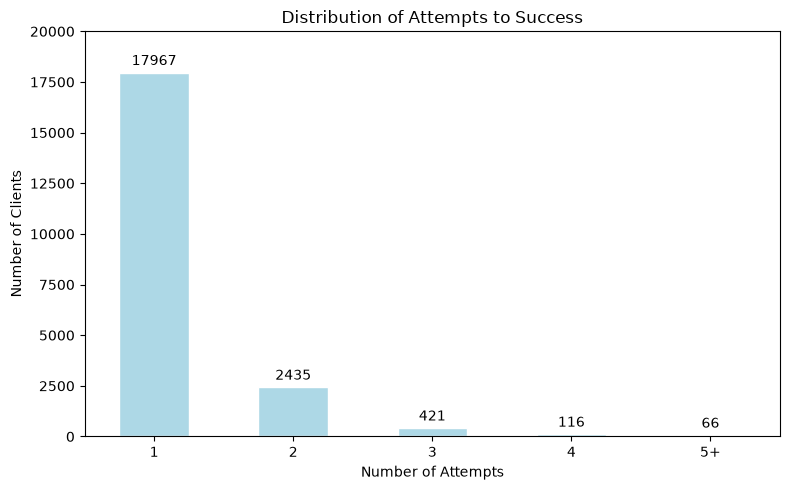

In [16]:
# Visualising the distribution of attempts to success

first_success["attempts_to_success"].clip(
    upper=5
).value_counts().sort_index().plot(
    kind="bar",
    color="lightblue",
    edgecolor="white",
    figsize=(8, 5)
)

plt.title("Distribution of Attempts to Success")
plt.xlabel("Number of Attempts")
plt.ylabel("Number of Clients")
plt.xticks(
    [0, 1, 2, 3, 4],
    ["1", "2", "3", "4", "5+"],
    rotation=0
)

for container in plt.gca().containers:
    plt.bar_label(container, fmt="%d", padding=3)

plt.ylim(0, 20000)
plt.tight_layout()
plt.savefig("../figures/distribution_attempts.png", dpi=300, bbox_inches="tight")
plt.show()

In [17]:
first_success["attempts_to_success"].describe().round(2)

count    21005.00
mean         1.19
std          0.58
min          1.00
25%          1.00
50%          1.00
75%          1.00
max         18.00
Name: attempts_to_success, dtype: float64

We have 21,005 clients who successfully completed
the process at least once.

On average, these clients needed 1.19 attempts
to achieve their first successful process.

### 4. Preparing the Client Data

In [18]:
clients_data = clients_data[clients_data["variation"].isin(["Control", "Test"])]
clients_data["variation"].value_counts(dropna=False)

variation
Test       26968
Control    23532
Name: count, dtype: int64

In [19]:
# Adding the 'attempts_to_success' column to our clients table

clients_h2 = clients_data.merge(first_success, on="client_id", how="left")

clients_h2.head()

,client_id,tenure_year,tenure_month,age,gender,accounts,balance,calls,logons,variation,attempts_to_success
0,555,3.0,46.0,29.5,U,2.0,25454.66,2.0,6.0,Test,1.0
1,647,12.0,151.0,57.5,M,2.0,30525.80,0.0,4.0,Test,NaN
2,934,9.0,109.0,51.0,F,2.0,32522.88,0.0,3.0,Test,NaN
3,1028,12.0,145.0,36.0,M,3.0,103520.22,1.0,4.0,Control,NaN
4,1104,5.0,66.0,48.0,U,3.0,154643.94,6.0,9.0,Control,NaN


In [20]:
clients_h2.info()

<class 'pandas.DataFrame'>
RangeIndex: 50500 entries, 0 to 50499
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   client_id            50500 non-null  int64  
 1   tenure_year          50488 non-null  float64
 2   tenure_month         50488 non-null  float64
 3   age                  50487 non-null  float64
 4   gender               50500 non-null  str    
 5   accounts             50488 non-null  float64
 6   balance              50488 non-null  float64
 7   calls                50488 non-null  float64
 8   logons               50488 non-null  float64
 9   variation            50500 non-null  str    
 10  attempts_to_success  21005 non-null  float64
dtypes: float64(8), int64(1), str(2)
memory usage: 4.5 MB


In [21]:
clients_h2["attempts_to_success"].isna().sum()

# Null values indicate clients who did not achieve any successful process during the observation period.

np.int64(29495)

In [22]:
# Checking the number of clients in each variation

clients_h2["variation"].value_counts(dropna=False)

variation
Test       26968
Control    23532
Name: count, dtype: int64

In [23]:
# Identifying clients who successfully completed the process

clients_h2["successful_client"] = (
    clients_h2["attempts_to_success"].notna()
)

clients_h2["successful_client"].value_counts()

successful_client
False    29495
True     21005
Name: count, dtype: int64

### 5. Exploring the Age Distribution

In [24]:
# Checking our age dataset

print("Clients with missing age:", clients_h2["age"].isna().sum())
clients_h2["age"].describe().round(2)

Clients with missing age: 13


count    50487.00
mean        47.32
std         15.52
min         17.00
25%         33.50
50%         48.00
75%         59.50
max         96.00
Name: age, dtype: float64

There are 13 clients with missing age information.

We will keep these clients in our dataset, but they
will not be included in our age analysis.

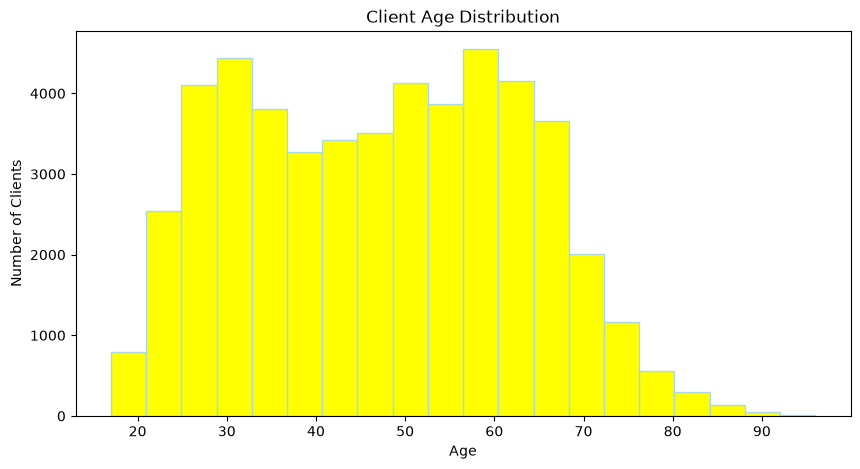

In [25]:
# Visualizing the distribution

plt.figure(figsize=(10, 5))
plt.hist(clients_h2["age"].dropna(), bins=20, color="yellow",edgecolor="lightblue")
plt.title("Client Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Clients")
plt.savefig("../figures/age_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

Looking at the histogram, we can see two peaks around
the ages of 30 and 60.

We can also see that there are fewer clients above
the age of 70.

In [26]:
# Checking the age difference between successful and unsuccessful clients

print("Successful clients:")
display(clients_h2[clients_h2["attempts_to_success"].notna()]["age"].describe().round(2))
print("\nUnsuccessful clients:")
display(clients_h2[clients_h2["attempts_to_success"].isna()]["age"].describe().round(2))

Successful clients:


count    21001.00
mean        44.39
std         14.96
min         17.00
25%         31.50
50%         43.50
75%         56.50
max         94.50
Name: age, dtype: float64


Unsuccessful clients:


count    29486.00
mean        49.41
std         15.57
min         17.50
25%         36.00
50%         51.00
75%         61.50
max         96.00
Name: age, dtype: float64

Clients who successfully completed the process are,
on average, around 5 years younger than clients who
did not succeed.

This is our first indication that age may be related
to the success of the process.

In [27]:
# Comparing client ages by success and variation

age_by_variation = clients_h2.pivot_table(
    index="successful_client",
    columns="variation",
    values="age",
    aggfunc=["mean", "median", "count"]
)

display(age_by_variation.round(2))

mean         median         count       
variation         Control   Test Control  Test Control   Test
successful_client                                            
False               49.42  49.40    51.0  51.0   14279  15207
True                44.53  44.28    43.5  43.0    9247  11754

In [28]:
# Calculating the age difference between unsuccessful and successful clients

age_difference = (
    age_by_variation.loc[False] -
    age_by_variation.loc[True]
)

display(age_difference[["mean", "median"]].round(2))

        variation
mean    Control      4.88
        Test         5.12
median  Control      7.50
        Test         8.00
dtype: float64

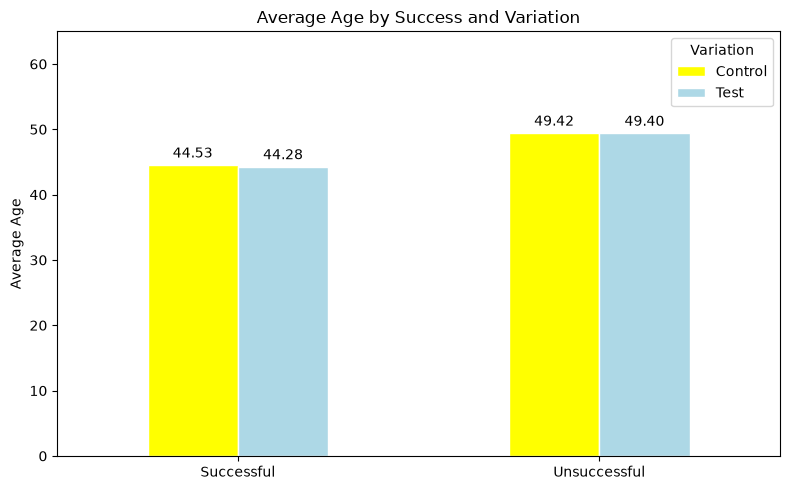

In [29]:
# Visualising average age by success and variation

age_by_variation["mean"].rename(
    index={True: "Successful", False: "Unsuccessful"}
).loc[["Successful", "Unsuccessful"]].plot(
    kind="bar",
    color=["yellow", "lightblue"],
    figsize=(8, 5),
    edgecolor="white"
)

plt.title("Average Age by Success and Variation")
plt.ylabel("Average Age")
plt.xlabel("")
plt.xticks(rotation=0)
plt.ylim(0, 65)
plt.legend(title="Variation")

# Adding numerical labels
for container in plt.gca().containers:
    plt.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.savefig("../figures/avg_age_by_success_var.png", dpi=300, bbox_inches="tight")
plt.show()

#### Comparing Ages by Variation

In both the Test and Control groups, successful clients
are around 5 years younger than unsuccessful clients
on average.

The difference in average age is 4.88 years in the
Control group and 5.12 years in the Test group.

We can see a similar pattern in both variations.

However, we need to look at the success rates and
number of attempts for each age group to better
understand if the new interface improves the
experience for older clients.

In [30]:
# Comparing age and attempts to success by variation

age_attempts_variation = clients_h2.pivot_table(
    index="attempts_to_success",
    columns="variation",
    values="age",
    aggfunc=["mean", "median", "count"]
)

display(age_attempts_variation.round(2))

mean         median          count         
variation           Control   Test Control   Test Control     Test
attempts_to_success                                               
1.0                   44.00  43.72   43.00  42.50  7841.0  10125.0
2.0                   46.78  47.10   47.50  48.50  1125.0   1308.0
3.0                   50.40  49.72   51.50  52.75   178.0    242.0
4.0                   52.31  51.12   54.25  52.75    58.0     58.0
5.0                   47.00  54.29   45.00  59.50    17.0      7.0
6.0                   52.83  63.08   55.00  66.50     6.0      6.0
7.0                   50.75  52.12   54.50  51.25    10.0      4.0
8.0                   40.20  57.25   37.50  57.25     5.0      2.0
9.0                   45.25  58.00   45.25  58.00     2.0      1.0
11.0                    NaN  62.50     NaN  62.50     NaN      1.0
12.0                  53.00    NaN   53.00    NaN     2.0      NaN
13.0                  30.00    NaN   30.00    NaN     1.0      NaN
14.0                  68.00    NaN   68.00    NaN     1.0      NaN
18.0                  71.00    NaN   71.00    NaN     1.0      NaN

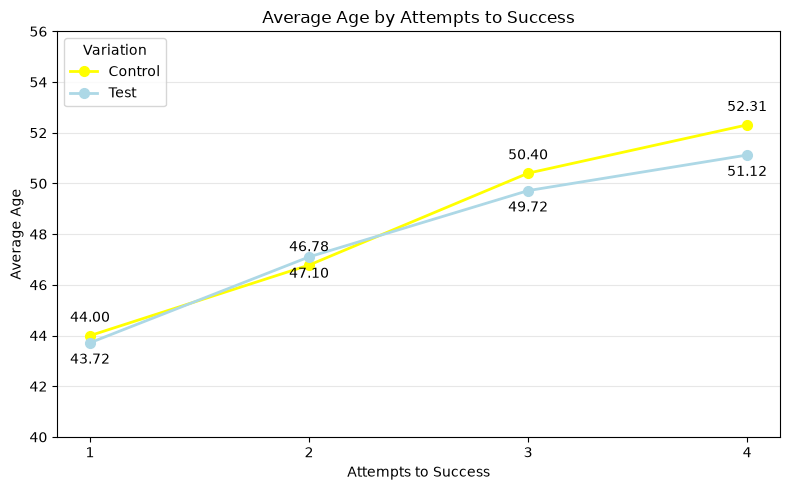

In [31]:
# Visualising average age for the first four attempts

age_attempts_variation["mean"][["Control", "Test"]].loc[1:4].plot(
    kind="line",
    marker="o",
    linewidth=2,
    markersize=7,
    color=["yellow", "lightblue"],
    figsize=(8, 5)
)

plt.title("Average Age by Attempts to Success")
plt.xlabel("Attempts to Success")
plt.ylabel("Average Age")
plt.xticks([1, 2, 3, 4])
plt.ylim(40, 56)
plt.legend(title="Variation")
plt.grid(axis="y", alpha=0.3)

# Adding numerical labels
for line in plt.gca().get_lines():
    for x, y in zip(line.get_xdata(), line.get_ydata()):
        plt.annotate(
            f"{y:.2f}",
            (x, y),
            textcoords="offset points",
            xytext=(0, 10 if line.get_label() == "Control" else -15),
            ha="center"
        )

plt.tight_layout()
plt.savefig("../figures/avg_age_by_attempts.png", dpi=300, bbox_inches="tight")
plt.show()

#### Comparing Age and Attempts by Variation

In both the Test and Control groups, the average age
increases with the number of attempts for the first
four attempts.

The average age increases from 44 to 52.31 years in
the Control group and from 43.72 to 51.12 years in
the Test group.

Both variations follow a similar pattern, suggesting
that the relationship between age and the number of
attempts is present regardless of the interface used.

From the fifth attempt onwards, the number of clients
is considerably smaller, making the results less
reliable for identifying a general trend.

### 6. Comparing Age Groups

In [32]:
# Checking median age to divide the clients in two groups, older and younger

median_age = clients_h2["age"].median()

print(f"Median age: {median_age} years old.")

Median age: 48.0 years old.


We decided to use the median age (48 years) to divide
our clients into two groups:

- Younger: clients under 48 years old.
- Older: clients aged 48 or above.

By using the median, we can create two groups with
a similar number of clients.

In [33]:
# Creating a new column separating the clients into younger or older groups

clients_h2["age_category"] = pd.cut(clients_h2["age"], bins=[0, median_age, np.inf], labels=["Younger", "Older"], right=False)

clients_h2["age_category"].value_counts()

age_category
Older      25453
Younger    25034
Name: count, dtype: int64

In [34]:
# Compare attempts results

clients_h2.groupby("age_category", observed=True)["attempts_to_success"].agg(["count", "mean", "median", "std"]).round(3)

,count,mean,median,std
age_category,,,,
Younger,12258,1.149,1.0,0.486
Older,8743,1.250,1.0,0.686


In [35]:
# Calculating success rate by age group
total_clients = clients_h2.groupby("age_category", observed=True)["client_id"].count()

successful_clients = clients_h2.groupby("age_category", observed=True)["attempts_to_success"].count()

success_rate = (successful_clients / total_clients * 100).round(2)
display(success_rate)

success_rate_difference = success_rate["Younger"] - success_rate["Older"]
print(f"\nDifference in success rates: {success_rate_difference:.2f} percentage points")

age_category
Younger    48.97
Older      34.35
dtype: float64


Difference in success rates: 14.62 percentage points


In [36]:
# Difference in average attempts

mean_attempts = clients_h2.groupby("age_category", observed=True)["attempts_to_success"].mean()

attempts_difference = ((mean_attempts["Older"] - mean_attempts["Younger"]) / mean_attempts["Younger"] * 100)

print(f"Older successful clients require {attempts_difference:.2f}% more attempts on average.")

Older successful clients require 8.83% more attempts on average.


#### Preliminary Findings

We divided our clients into two age groups:

- Younger clients: 25,034
- Older clients: 25,453

#### Findings

- Younger successful clients need an average of
  1.149 attempts, while older successful clients
  need an average of 1.250 attempts.

- Older successful clients need around 8.8% more
  attempts to successfully complete the process.

- Both groups have a median of 1 attempt.

- Older successful clients have a higher standard
  deviation (0.686 compared to 0.486), meaning
  there is more variation in the number of attempts
  they need.

- Younger clients have a success rate of 48.97%,
  while older clients have a success rate of 34.35%.

- There is a difference of 14.62 percentage points
  between the two success rates.

#### Preliminary conclusion

Our results suggest that younger clients are more
likely to succeed and need fewer attempts when
they do succeed.

However, we still need to perform a statistical
test to check if the difference in the average
number of attempts is statistically significant.

#### Comparing Age Groups by Variation

We now want to understand if the new interface
improves the success rate and reduces the number
of attempts for both age groups.

We also want to check if the new interface helps
reduce the performance gap between younger and
older clients.

In [37]:
# Comparing age group performance by variation

age_group_variation = clients_h2.pivot_table(
    index="age_category",
    columns="variation",
    values=[
        "successful_client",
        "attempts_to_success",
        "client_id"
    ],
    aggfunc={
        "successful_client": "mean",
        "attempts_to_success": "mean",
        "client_id": "count"
    },
    observed=True
)

display(age_group_variation.round(4))

attempts_to_success         client_id        successful_client  \
variation                Control    Test   Control   Test           Control   
age_category                                                                  
Younger                   1.1674  1.1341     11534  13500            0.4646   
Older                     1.2652  1.2379     11992  13461            0.3242   

                      
variation       Test  
age_category          
Younger       0.5110  
Older         0.3607

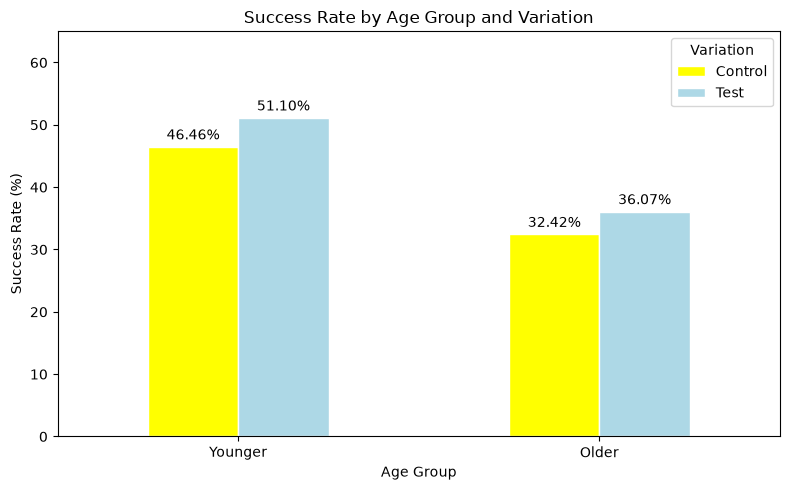

In [38]:
# Visualising success rates by age group and variation

age_group_variation["successful_client"][["Control", "Test"]].mul(100).plot(
    kind="bar",
    color=["yellow", "lightblue"],
    figsize=(8, 5),
    edgecolor="white"
)

plt.title("Success Rate by Age Group and Variation")
plt.xlabel("Age Group")
plt.ylabel("Success Rate (%)")
plt.xticks(rotation=0)
plt.ylim(0, 65)
plt.legend(title="Variation")

# Adding numerical labels
for container in plt.gca().containers:
    plt.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.savefig("../figures/success_rate_by_age_var.png", dpi=300, bbox_inches="tight")
plt.show()

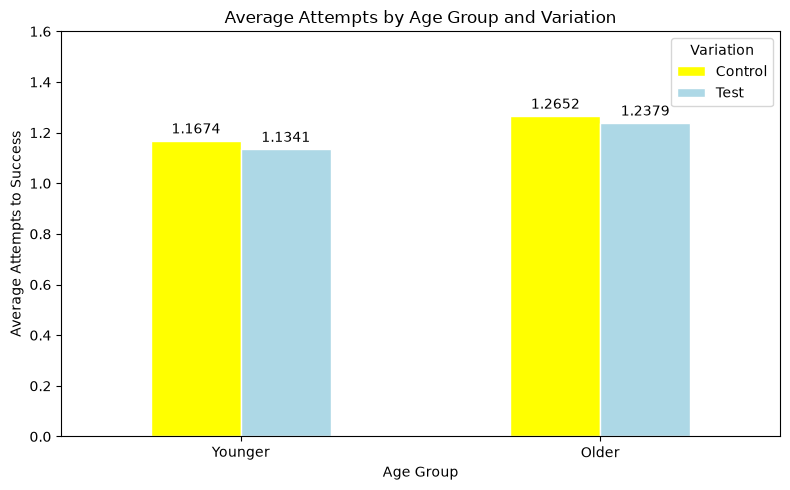

In [39]:
# Visualising average attempts by age group and variation

age_group_variation["attempts_to_success"][["Control", "Test"]].plot(
    kind="bar",
    color=["yellow", "lightblue"],
    figsize=(8, 5),
    edgecolor="white"
)

plt.title("Average Attempts by Age Group and Variation")
plt.xlabel("Age Group")
plt.ylabel("Average Attempts to Success")
plt.xticks(rotation=0)
plt.ylim(0, 1.6)
plt.legend(title="Variation")

# Adding numerical labels
for container in plt.gca().containers:
    plt.bar_label(container, fmt="%.4f", padding=3)

plt.tight_layout()
plt.savefig("../figures/avg_attemps_by_age_var.png", dpi=300, bbox_inches="tight")
plt.show()

In [40]:
# Calculating the improvement in success rates
# and the difference in average attempts

age_group_variation["success_rate_difference_pp"] = (
    age_group_variation["successful_client"]["Test"] -
    age_group_variation["successful_client"]["Control"]
) * 100

age_group_variation["attempts_difference"] = (
    age_group_variation["attempts_to_success"]["Test"] -
    age_group_variation["attempts_to_success"]["Control"]
)

display(age_group_variation.round(4))

attempts_to_success         client_id        successful_client  \
variation                Control    Test   Control   Test           Control   
age_category                                                                  
Younger                   1.1674  1.1341     11534  13500            0.4646   
Older                     1.2652  1.2379     11992  13461            0.3242   

                     success_rate_difference_pp attempts_difference  
variation       Test                                                 
age_category                                                         
Younger       0.5110                     4.6411             -0.0333  
Older         0.3607                     3.6455             -0.0273

In [41]:
# Calculating the success rate gap between age groups

success_rate_gap = (
    age_group_variation["successful_client"].loc["Younger"] -
    age_group_variation["successful_client"].loc["Older"]
) * 100

print("Success Rate Gap:")
display(success_rate_gap.round(2))

# Calculating the average attempts gap between age groups

attempts_gap = (
    age_group_variation["attempts_to_success"].loc["Older"] -
    age_group_variation["attempts_to_success"].loc["Younger"]
)
print("\nAverage Attempts Gap:")
display(attempts_gap.round(4))

Success Rate Gap:


variation
Control    14.04
Test       15.04
dtype: float64


Average Attempts Gap:


variation
Control    0.0978
Test       0.1038
dtype: float64

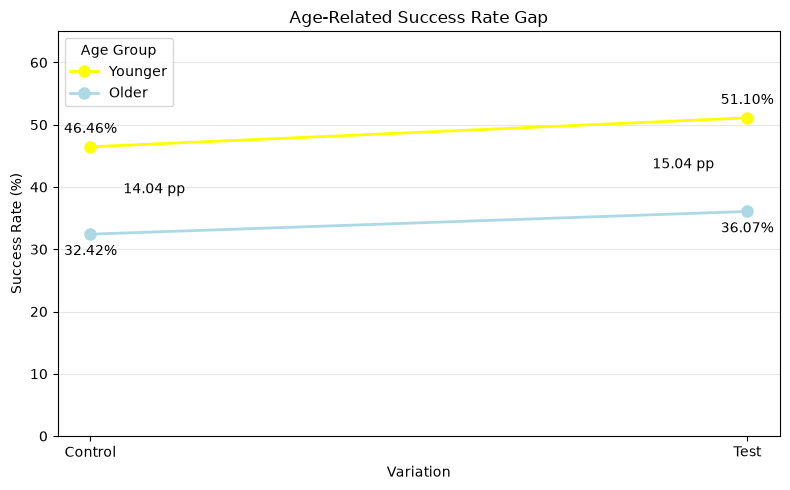

In [42]:
# Visualising the success rate gap between age groups

age_group_variation["successful_client"][["Control", "Test"]].loc[
    ["Younger", "Older"]
].T.mul(100).plot(
    kind="line",
    marker="o",
    linewidth=2,
    markersize=8,
    color=["yellow", "lightblue"],
    figsize=(8, 5)
)

plt.title("Age-Related Success Rate Gap")
plt.xlabel("Variation")
plt.ylabel("Success Rate (%)")
plt.xticks([0, 1], ["Control", "Test"])
plt.ylim(0, 65)
plt.legend(title="Age Group")
plt.grid(axis="y", alpha=0.3)

# Adding percentage labels
for line in plt.gca().get_lines():
    for x, y in zip(line.get_xdata(), line.get_ydata()):
        plt.annotate(
            f"{y:.2f}%",
            (x, y),
            textcoords="offset points",
            xytext=(0, 10 if line.get_label() == "Younger" else -15),
            ha="center"
        )

# Adding the success rate gap
plt.text(0.05, 39, f"{success_rate_gap['Control']:.2f} pp")
plt.text(0.95, 43, f"{success_rate_gap['Test']:.2f} pp", ha="right")

plt.tight_layout()
plt.savefig("../figures/age_success_rate.png", dpi=300, bbox_inches="tight")
plt.show()

#### Findings by Age Group and Variation

The Test group shows better results for both age
groups, with higher success rates and fewer attempts
to success.

The success rate increases by 4.64 percentage points
for younger clients and 3.65 percentage points for
older clients.

Both age groups also show a reduction in the average
number of attempts needed to succeed, with a slightly
greater reduction among younger clients.

However, the difference in success rates between
younger and older clients increases from 14.04
percentage points in the Control group to 15.04
in the Test group.

The difference in average attempts also increases
slightly, from 0.0978 to 0.1038.

These results suggest that although the new interface
improves performance for both age groups, it does not
appear to reduce the age-related performance gap.

Further statistical testing is needed to understand
whether the observed differences are statistically
significant.

### 7. Statistical Hypothesis Testing

**H0 (Null hypothesis):** Among successful clients,
younger clients need the same or a higher average
number of attempts than older clients.

**H1 (Alternative hypothesis):** Among successful clients,
younger clients need fewer attempts on average than
older clients.

**Significance level (alpha):** 0.05

We decided to use a one-tailed Welch's t-test because:

- We are comparing the averages of two independent groups.
- The groups have different variances.
- Both groups have a large number of clients.
- We want to test if younger clients need fewer
  attempts, not just if there is a difference.

If the p-value is below 0.05, we will reject
the null hypothesis.

In [43]:
# creating 2 independent samples

younger = clients_h2[clients_h2["age_category"] == "Younger"]["attempts_to_success"].dropna()

older = clients_h2[clients_h2["age_category"] == "Older"]["attempts_to_success"].dropna()

print("Younger clients:", len(younger))
print("Older clients:", len(older))

Younger clients: 12258
Older clients: 8743


In [44]:
statistic, p_value = stats.ttest_ind(
    younger,
    older,
    equal_var=False,
    alternative="less"
)

print("Test statistic:", statistic)
print("P-value:", p_value)

Test statistic: -11.858736893280275
P-value: 1.3587794687787136e-32


In [45]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

Reject the null hypothesis.


#### Statistical Results and Conclusion

##### Statistical results

- Test statistic: -11.8587
- P-value: 1.3588e-32
- Significance level: 0.05

As our p-value is below 0.05, we reject the null
hypothesis.

##### Conclusion

Our results support our initial hypothesis (H2).

Among successful clients, younger clients need fewer
attempts on average than older clients.

Our statistical test shows that this difference
is statistically significant.

We also found that younger clients have a higher
success rate.

This suggests that older clients may experience
more difficulties when using Vanguard's digital
platform.

#### Statistical Hypothesis Testing by Variation

After testing our hypothesis for the overall
population, we now want to understand if the
same hypothesis is supported in both the Test
and Control groups.

H0: Younger clients need the same number of attempts
or more than older clients to successfully complete
the process.

H1: Younger clients need fewer attempts than older
clients to successfully complete the process.

In [46]:
# Creating age group samples for each variation

younger_control = clients_h2[
    (clients_h2["age_category"] == "Younger") &
    (clients_h2["variation"] == "Control")
]["attempts_to_success"].dropna()

older_control = clients_h2[
    (clients_h2["age_category"] == "Older") &
    (clients_h2["variation"] == "Control")
]["attempts_to_success"].dropna()

younger_test = clients_h2[
    (clients_h2["age_category"] == "Younger") &
    (clients_h2["variation"] == "Test")
]["attempts_to_success"].dropna()

older_test = clients_h2[
    (clients_h2["age_category"] == "Older") &
    (clients_h2["variation"] == "Test")
]["attempts_to_success"].dropna()

In [47]:
# Performing Welch's t-test for the Control group

t_stat_control, p_value_control = stats.ttest_ind(
    younger_control,
    older_control,
    equal_var=False,
    alternative="less"
)

print("T-statistic:", t_stat_control)
print("P-value:", p_value_control)

T-statistic: -6.767917539547462
P-value: 7.086766744938284e-12


In [48]:
# Performing Welch's t-test for the Test group

t_stat_test, p_value_test = stats.ttest_ind(
    younger_test,
    older_test,
    equal_var=False,
    alternative="less"
)

print("T-statistic:", t_stat_test)
print("P-value:", p_value_test)

T-statistic: -10.201644395301974
P-value: 1.3704072942783732e-24


In [49]:
# Evaluating the statistical results for both variations

alpha = 0.05

if p_value_control < alpha:
    print("Control: Reject the null hypothesis.")
else:
    print("Control: Fail to reject the null hypothesis.")

if p_value_test < alpha:
    print("Test: Reject the null hypothesis.")
else:
    print("Test: Fail to reject the null hypothesis.")

Control: Reject the null hypothesis.
Test: Reject the null hypothesis.


#### Statistical Results by Variation

Both the Test and Control groups have p-values below
our significance level of 0.05.

Therefore, we reject the null hypothesis for both
variations.

The results support our hypothesis that younger
clients need fewer attempts than older clients
to successfully complete the process.

This shows that the relationship between age and
attempts to success is present in both variations,
regardless of the interface used.

However, these tests do not tell us whether the
new interface significantly reduces or increases
the performance gap between age groups.

This analysis only includes clients who successfully
completed the process.

### 8. Additional Exploratory Analysis

#### 8.1 Account Balance and Attempts to Success

We want to explore whether clients with higher account
balances need more attempts to successfully complete
the process.

In [50]:
# Comparing account balances and attempts by variation

balance_attempts = clients_h2.pivot_table(
    index="attempts_to_success",
    columns="variation",
    values="balance",
    aggfunc=["count", "mean", "median"]
)

display(balance_attempts.round(2))

count                mean                  median  \
variation           Control     Test    Control         Test    Control   
attempts_to_success                                                       
1.0                  7841.0  10125.0  136387.08    134549.09   60156.28   
2.0                  1125.0   1308.0  168048.99    169397.37   74400.15   
3.0                   178.0    242.0  174767.47    183201.14   72129.44   
4.0                    58.0     58.0  220838.16    169035.79  104183.92   
5.0                    17.0      7.0  133986.19    133251.06   78103.86   
6.0                     6.0      6.0  376807.00    260599.01  112626.74   
7.0                    10.0      4.0  159369.35     84071.77   96685.18   
8.0                     5.0      2.0   73777.46    135022.67   68672.57   
9.0                     2.0      1.0   93783.14    210135.34   93783.14   
11.0                    NaN      1.0        NaN  16320040.15        NaN   
12.0                    2.0      NaN  480859.25          NaN  480859.25   
13.0                    1.0      NaN   47214.71          NaN   47214.71   
14.0                    1.0      NaN  149367.17          NaN  149367.17   
18.0                    1.0      NaN   53955.97          NaN   53955.97   

                                  
variation                   Test  
attempts_to_success               
1.0                     60333.05  
2.0                     71486.96  
3.0                     86045.41  
4.0                     85122.20  
5.0                     65036.19  
6.0                    200815.38  
7.0                     70530.78  
8.0                    135022.67  
9.0                    210135.34  
11.0                 16320040.15  
12.0                         NaN  
13.0                         NaN  
14.0                         NaN  
18.0                         NaN

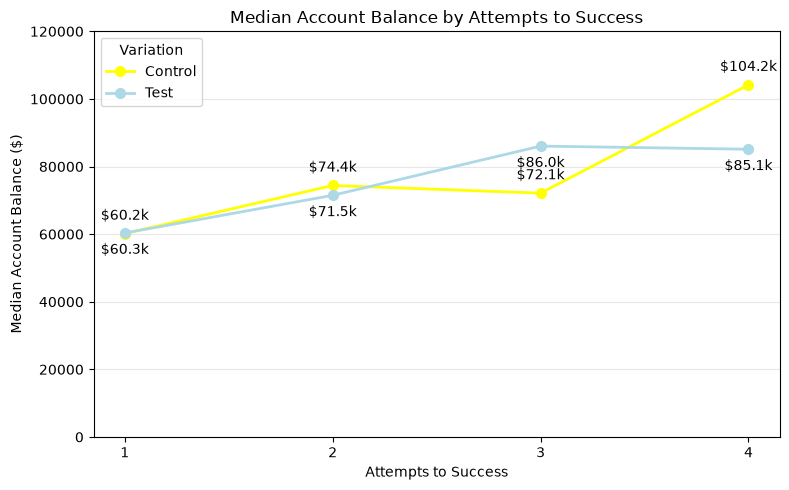

In [51]:
# Visualising median account balance by attempts to success

balance_attempts["median"][["Control", "Test"]].loc[1:4].plot(
    kind="line",
    marker="o",
    linewidth=2,
    markersize=7,
    color=["yellow", "lightblue"],
    figsize=(8, 5)
)

plt.title("Median Account Balance by Attempts to Success")
plt.xlabel("Attempts to Success")
plt.ylabel("Median Account Balance ($)")
plt.xticks([1, 2, 3, 4])
plt.ylim(0, 120000)
plt.legend(title="Variation")
plt.grid(axis="y", alpha=0.3)

# Adding numerical labels
for line in plt.gca().get_lines():
    for x, y in zip(line.get_xdata(), line.get_ydata()):
        plt.annotate(
            f"${y/1000:.1f}k",
            (x, y),
            textcoords="offset points",
            xytext=(0, 10 if line.get_label() == "Control" else -15),
            ha="center"
        )

plt.tight_layout()
plt.savefig("../figures/median_bal_by_attempts.png", dpi=300, bbox_inches="tight")
plt.show()

#### Findings

- Among successful clients, median account balances
  are generally higher for clients who need more attempts.
- This general pattern is observed in both variations
  across the first four attempts, although the increase
  is not consistent.
- Clients who succeed on their first attempt have a median
  balance of approximately $60,000 in both variations.
- From five attempts onwards, the sample sizes are too small
  to identify a reliable pattern.

**Business Insight**

Vanguard could investigate the difficulties experienced by
clients with higher account balances and consider providing
additional guidance during the digital process.

However, this relationship may also be influenced by other
factors, such as age or client tenure. Further analysis
would be needed to understand these relationships.

#### 8.2 Age and Number of Calls

We want to explore whether older clients tend to make
more calls to Vanguard than younger clients.

This could help us understand whether older clients
may need additional assistance.

In [52]:
# Comparing the number of calls by age group and variation

calls_by_age = clients_h2.pivot_table(
    index="age_category",
    columns="variation",
    values="calls",
    aggfunc=["count", "mean", "median"],
    observed=True
)

display(calls_by_age.round(2))

count           mean        median     
variation    Control   Test Control  Test Control Test
age_category                                          
Younger        11534  13500    3.05  2.95     3.0  3.0
Older          11992  13461    3.21  3.17     3.0  3.0

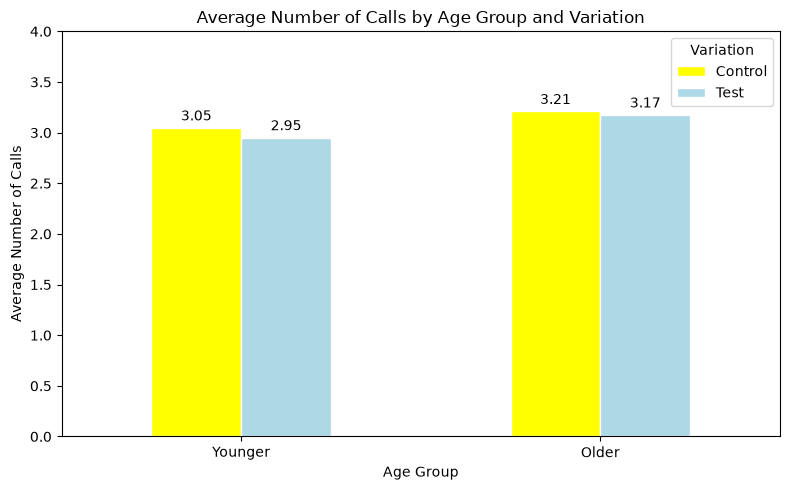

In [53]:
# Visualising average number of calls by age group and variation

calls_by_age["mean"][["Control", "Test"]].plot(
    kind="bar",
    color=["yellow", "lightblue"],
    figsize=(8, 5),
    edgecolor="white"
)

plt.title("Average Number of Calls by Age Group and Variation")
plt.xlabel("Age Group")
plt.ylabel("Average Number of Calls")
plt.xticks(rotation=0)
plt.ylim(0, 4)
plt.legend(title="Variation")

# Adding numerical labels
for container in plt.gca().containers:
    plt.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.savefig("../figures/avg_calls_by_age_var.png", dpi=300, bbox_inches="tight")
plt.show()

#### Findings

- Older clients make slightly more calls on average
  than younger clients in both variations.
- Clients in the Test group have a slightly lower
  average number of calls in both age groups.
- The median number of calls is 3 across all groups,
  suggesting that the differences are relatively small.

**Business Insight**

Considering our previous findings regarding age,
success rates and attempts, Vanguard could explore
additional digital guidance for older clients.

However, we cannot confirm whether these calls were
related to difficulties with the digital process
or whether the new interface reduced the need for
assistance.

### 9. Business Recommendations and Limitations

#### Business Recommendations

Our analysis shows that the Test group has higher
success rates and fewer average attempts among
successful clients in both age groups. However,
the age-related performance gap remains.

Based on our findings, we recommend that Vanguard considers the following improvements:

**1. Improve accessibility and navigation**

- Provide clearer instructions and simpler navigation.
- Improve the readability of text, buttons and instructions.
- Add a progress indicator to help clients understand where they are in the process.

**2. Provide additional digital assistance**

- Introduce optional step-by-step guidance.
- Make help and support easier to access without leaving the process.
- Consider interactive tutorials for clients who are less comfortable with digital platforms.

**3. Investigate difficulties among clients with higher account balances**

Our exploratory analysis suggests that clients who require more attempts tend to have higher account balances.

Vanguard could investigate the difficulties experienced by these clients and explore whether additional personalised assistance could improve their experience.

**4. Monitor the age-related performance gap**

Although the new interface improves performance for both age groups, the difference in success rates increases slightly from 14.04 to 15.04 percentage points.

We recommend monitoring the following KPIs by age group:

- Successful process rate.
- Average attempts to success.
- First-attempt success rate.
- Customer support requests.

This would help Vanguard understand whether future improvements benefit different customer segments.

#### Limitations

- Our statistical tests only include clients who successfully completed the process at least once.
- Unsuccessful clients are included in the success rate calculations but not in the average attempts to success.
- We can only analyse the attempts recorded in our dataset, not the client's entire history with Vanguard.
- We used the median age of 48 years to define younger and older clients.
- We did not statistically test the differences in success rates or the change in the performance gap between variations.
- The relationship between account balance and attempts is exploratory. Clients requiring five or more attempts represent very small samples.
- We cannot confirm whether the recorded calls were related to difficulties with the digital process or occurred during the experiment.
- Other factors, such as client tenure, digital experience and account complexity, may influence our results.
- The definition of a successful process depends on
  our selected criteria, including the 360-second
  threshold.
- The additional exploratory analyses are descriptive
  and have not been tested for statistical significance.

Although our findings support H2, we cannot conclude that age itself is the cause of these difficulties. Further analysis and user experience testing would help Vanguard better understand the reasons behind these differences.